In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
df = pd.read_csv("ecommerce_delivery_prediction.csv")

In [10]:
df.head()
df.isnull().sum()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Order_ID            5000 non-null   object 
 1   Order_Date          5000 non-null   object 
 2   Order_Hour          5000 non-null   int64  
 3   Product_Category    5000 non-null   object 
 4   Product_Weight_KG   4887 non-null   float64
 5   Product_Price_INR   4896 non-null   float64
 6   Seller_Region       5000 non-null   object 
 7   Customer_Region     5000 non-null   object 
 8   Seller_Rating       4903 non-null   float64
 9   Shipping_Method     5000 non-null   object 
 10  Distance_KM         5000 non-null   float64
 11  Payment_Method      4909 non-null   object 
 12  Customer_Type       4921 non-null   object 
 13  Package_Size        5000 non-null   object 
 14  Weather_Condition   4898 non-null   object 
 15  Is_Holiday          5000 non-null   int64  
 16  Wareho

,Order_Hour,Product_Weight_KG,Product_Price_INR,Seller_Rating,Distance_KM,Is_Holiday,Warehouse_Load_Pct,Delivery_Days
count,5000.000000,4887.000000,4896.000000,4903.000000,5000.000000,5000.000000,4875.000000,5000.00000
mean,15.083200,5.988324,19104.814018,4.090863,1037.957300,0.094200,61.659036,3.47440
std,4.890098,7.527714,25746.412187,0.448535,632.087837,0.292136,16.509160,1.51862
min,7.000000,0.100000,119.810000,2.500000,5.000000,0.000000,20.000000,1.00000
25%,11.000000,1.610000,3271.060000,3.780000,560.275000,0.000000,50.250000,2.00000
50%,15.000000,3.450000,7847.385000,4.090000,1051.200000,0.000000,61.900000,3.00000
75%,19.000000,7.185000,22016.197500,4.410000,1499.800000,0.000000,72.850000,4.00000
max,23.000000,39.910000,119879.250000,5.000000,2734.100000,1.000000,99.000000,9.00000


# Handle Missing Values

In [16]:
num_cols = df.select_dtypes(include=["number"]).columns
cat_cols = df.select_dtypes(include=["object"]).columns

In [17]:
num_imp = SimpleImputer(strategy="mean")
df[num_cols] = num_imp.fit_transform(df[num_cols])

cat_imp = SimpleImputer(strategy="most_frequent")
df[cat_cols] = cat_imp.fit_transform(df[cat_cols])

# EDA - exploratory data analysis

Text(0.5, 1.0, 'Distribution of Delivery Days')

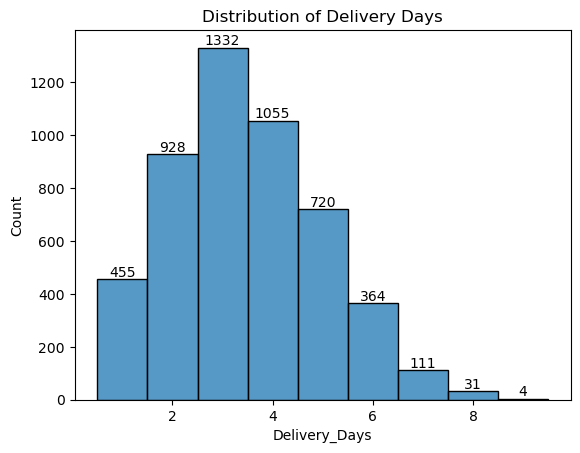

In [30]:
# Target distribution

ax = sns.histplot(data=df, x="Delivery_Days", discrete=True)
ax.bar_label(ax.containers[0])

plt.title("Distribution of Delivery Days")

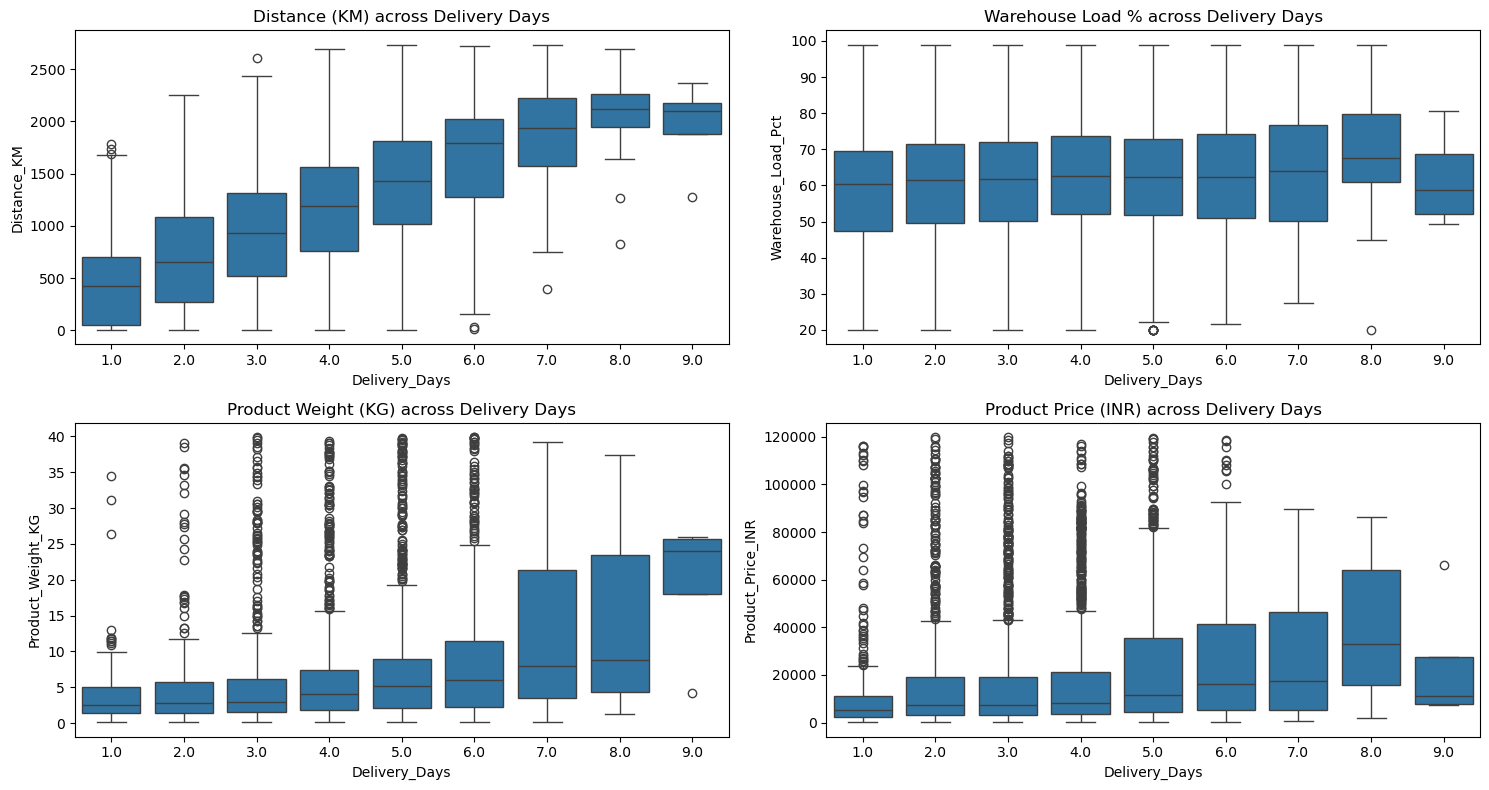

In [31]:
# Numerical relationships

figure, axes = plt.subplots(2, 2, figsize=(15,8))

sns.boxplot(ax=axes[0,0], data=df, x="Delivery_Days", y="Distance_KM")
axes[0, 0].set_title("Distance (KM) across Delivery Days")

sns.boxplot(ax=axes[0,1], data=df, x="Delivery_Days", y="Warehouse_Load_Pct")
axes[0, 1].set_title("Warehouse Load % across Delivery Days")

sns.boxplot(ax=axes[1,0], data=df, x="Delivery_Days", y="Product_Weight_KG")
axes[1, 0].set_title("Product Weight (KG) across Delivery Days")

sns.boxplot(ax=axes[1, 1], data=df, x="Delivery_Days", y="Product_Price_INR")
axes[1, 1].set_title("Product Price (INR) across Delivery Days")

plt.tight_layout()
plt.show()

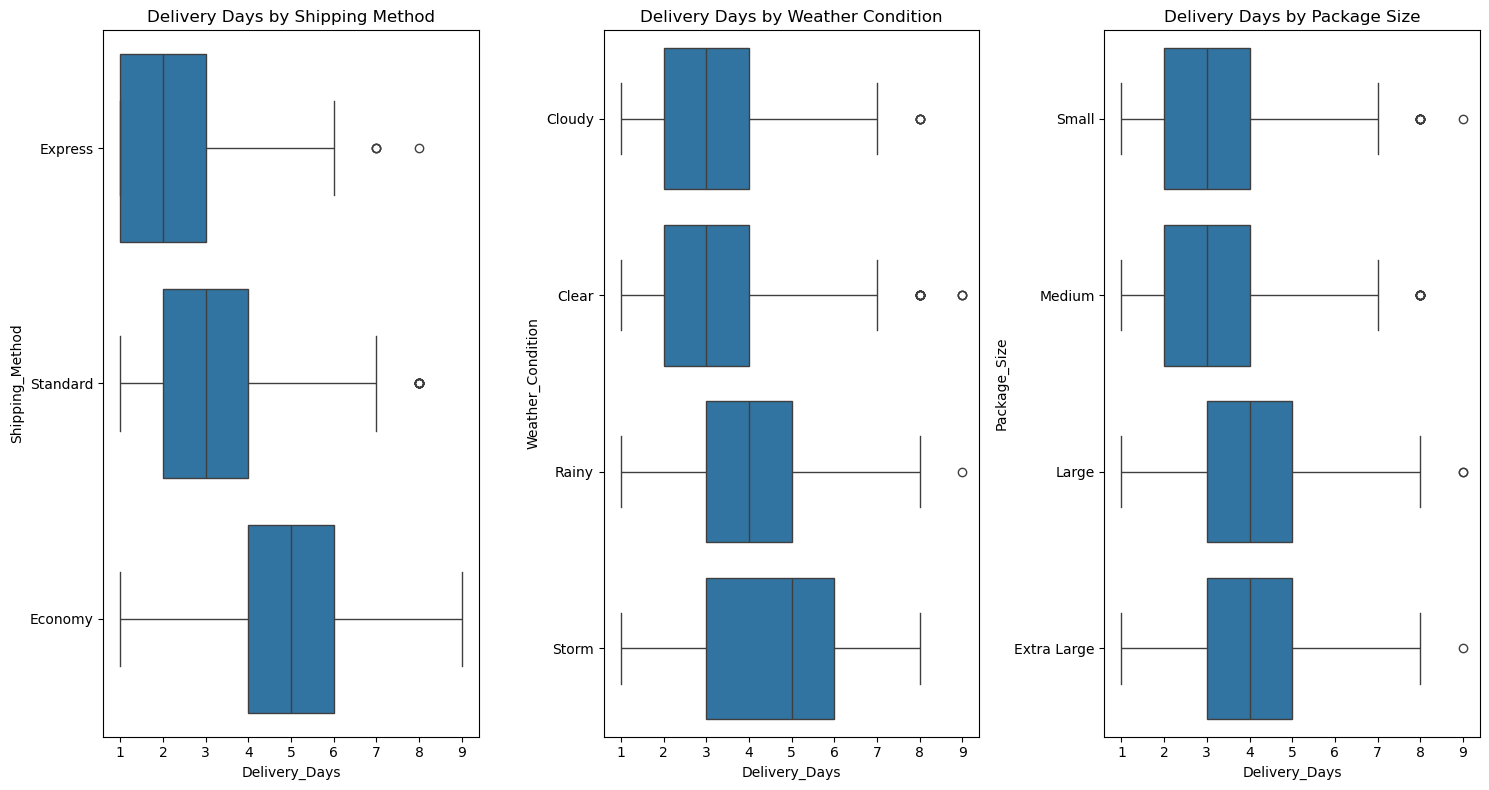

In [32]:
# Categorical relationships

figure, axes = plt.subplots(1, 3, figsize=(15,8))

sns.boxplot(ax=axes[0], data=df, x="Delivery_Days", y="Shipping_Method")
axes[0].set_title("Delivery Days by Shipping Method")

sns.boxplot(ax=axes[1], data=df, x="Delivery_Days", y="Weather_Condition")
axes[1].set_title("Delivery Days by Weather Condition")

sns.boxplot(ax=axes[2], data=df, x="Delivery_Days", y="Package_Size")
axes[2].set_title("Delivery Days by Package Size")

plt.tight_layout()
plt.show()

# Feature Engineering

In [43]:
# Date -> useful date feature

df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Order_DayOfWeek"] = df["Order_Date"].dt.dayofweek
df["Is_Weeked"] = df["Order_Date"].dt.dayofweek.isin([5, 6]).astype(int)
df["Order_Month"] = df["Order_Date"].dt.month
df["Order_Quarter"] = df["Order_Date"].dt.quarter
df["Order_Day"] = df["Order_Date"].dt.day
df["Is_Month_End"] = df["Order_Date"].dt.is_month_end.astype(int)

In [44]:
# Time → useful time features

df["Hour_Sin"] = np.sin(2 * np.pi * df["Order_Hour"]/24)
df["Hour_Cos"] = np.cos(2 * np.pi * df["Order_Hour"]/24)

In [45]:
# Distance features

df["Log_Distance_KM"] = np.log1p(df["Distance_KM"])

# Outliers

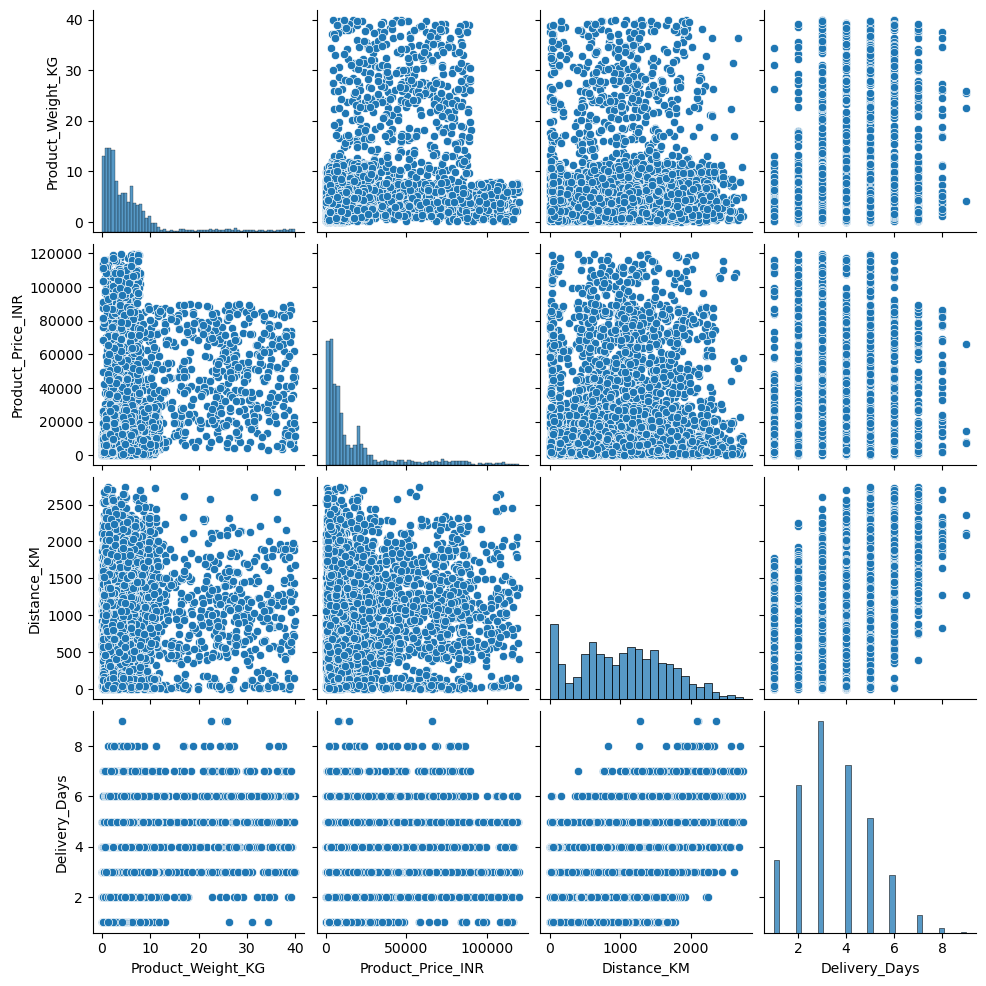

In [49]:
cols = ["Product_Weight_KG", "Product_Price_INR", "Distance_KM", "Delivery_Days"]

# relative plot of some features - pair plot

sns.pairplot(df[cols])

# Encoding

In [54]:
ordinal_cols = ["Package_Size"]
ordinal_cat = [["Small", "Medium", "Large", "Extra Large"]]

oe = OrdinalEncoder(categories=ordinal_cat)
df[ordinal_cols] = oe.fit_transform(df[ordinal_cols])

In [57]:
ohe_cols = ["Product_Category", "Seller_Region", "Customer_Region", "Shipping_Method", "Customer_Type", "Weather_Condition"]

ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
encoded_data = ohe.fit_transform(df[ohe_cols])

df_encoded = pd.DataFrame(encoded_data, columns=ohe.get_feature_names_out(ohe_cols), index=df.index)
df = pd.concat([df.drop(columns=ohe_cols), df_encoded], axis=1)

# Heatmap

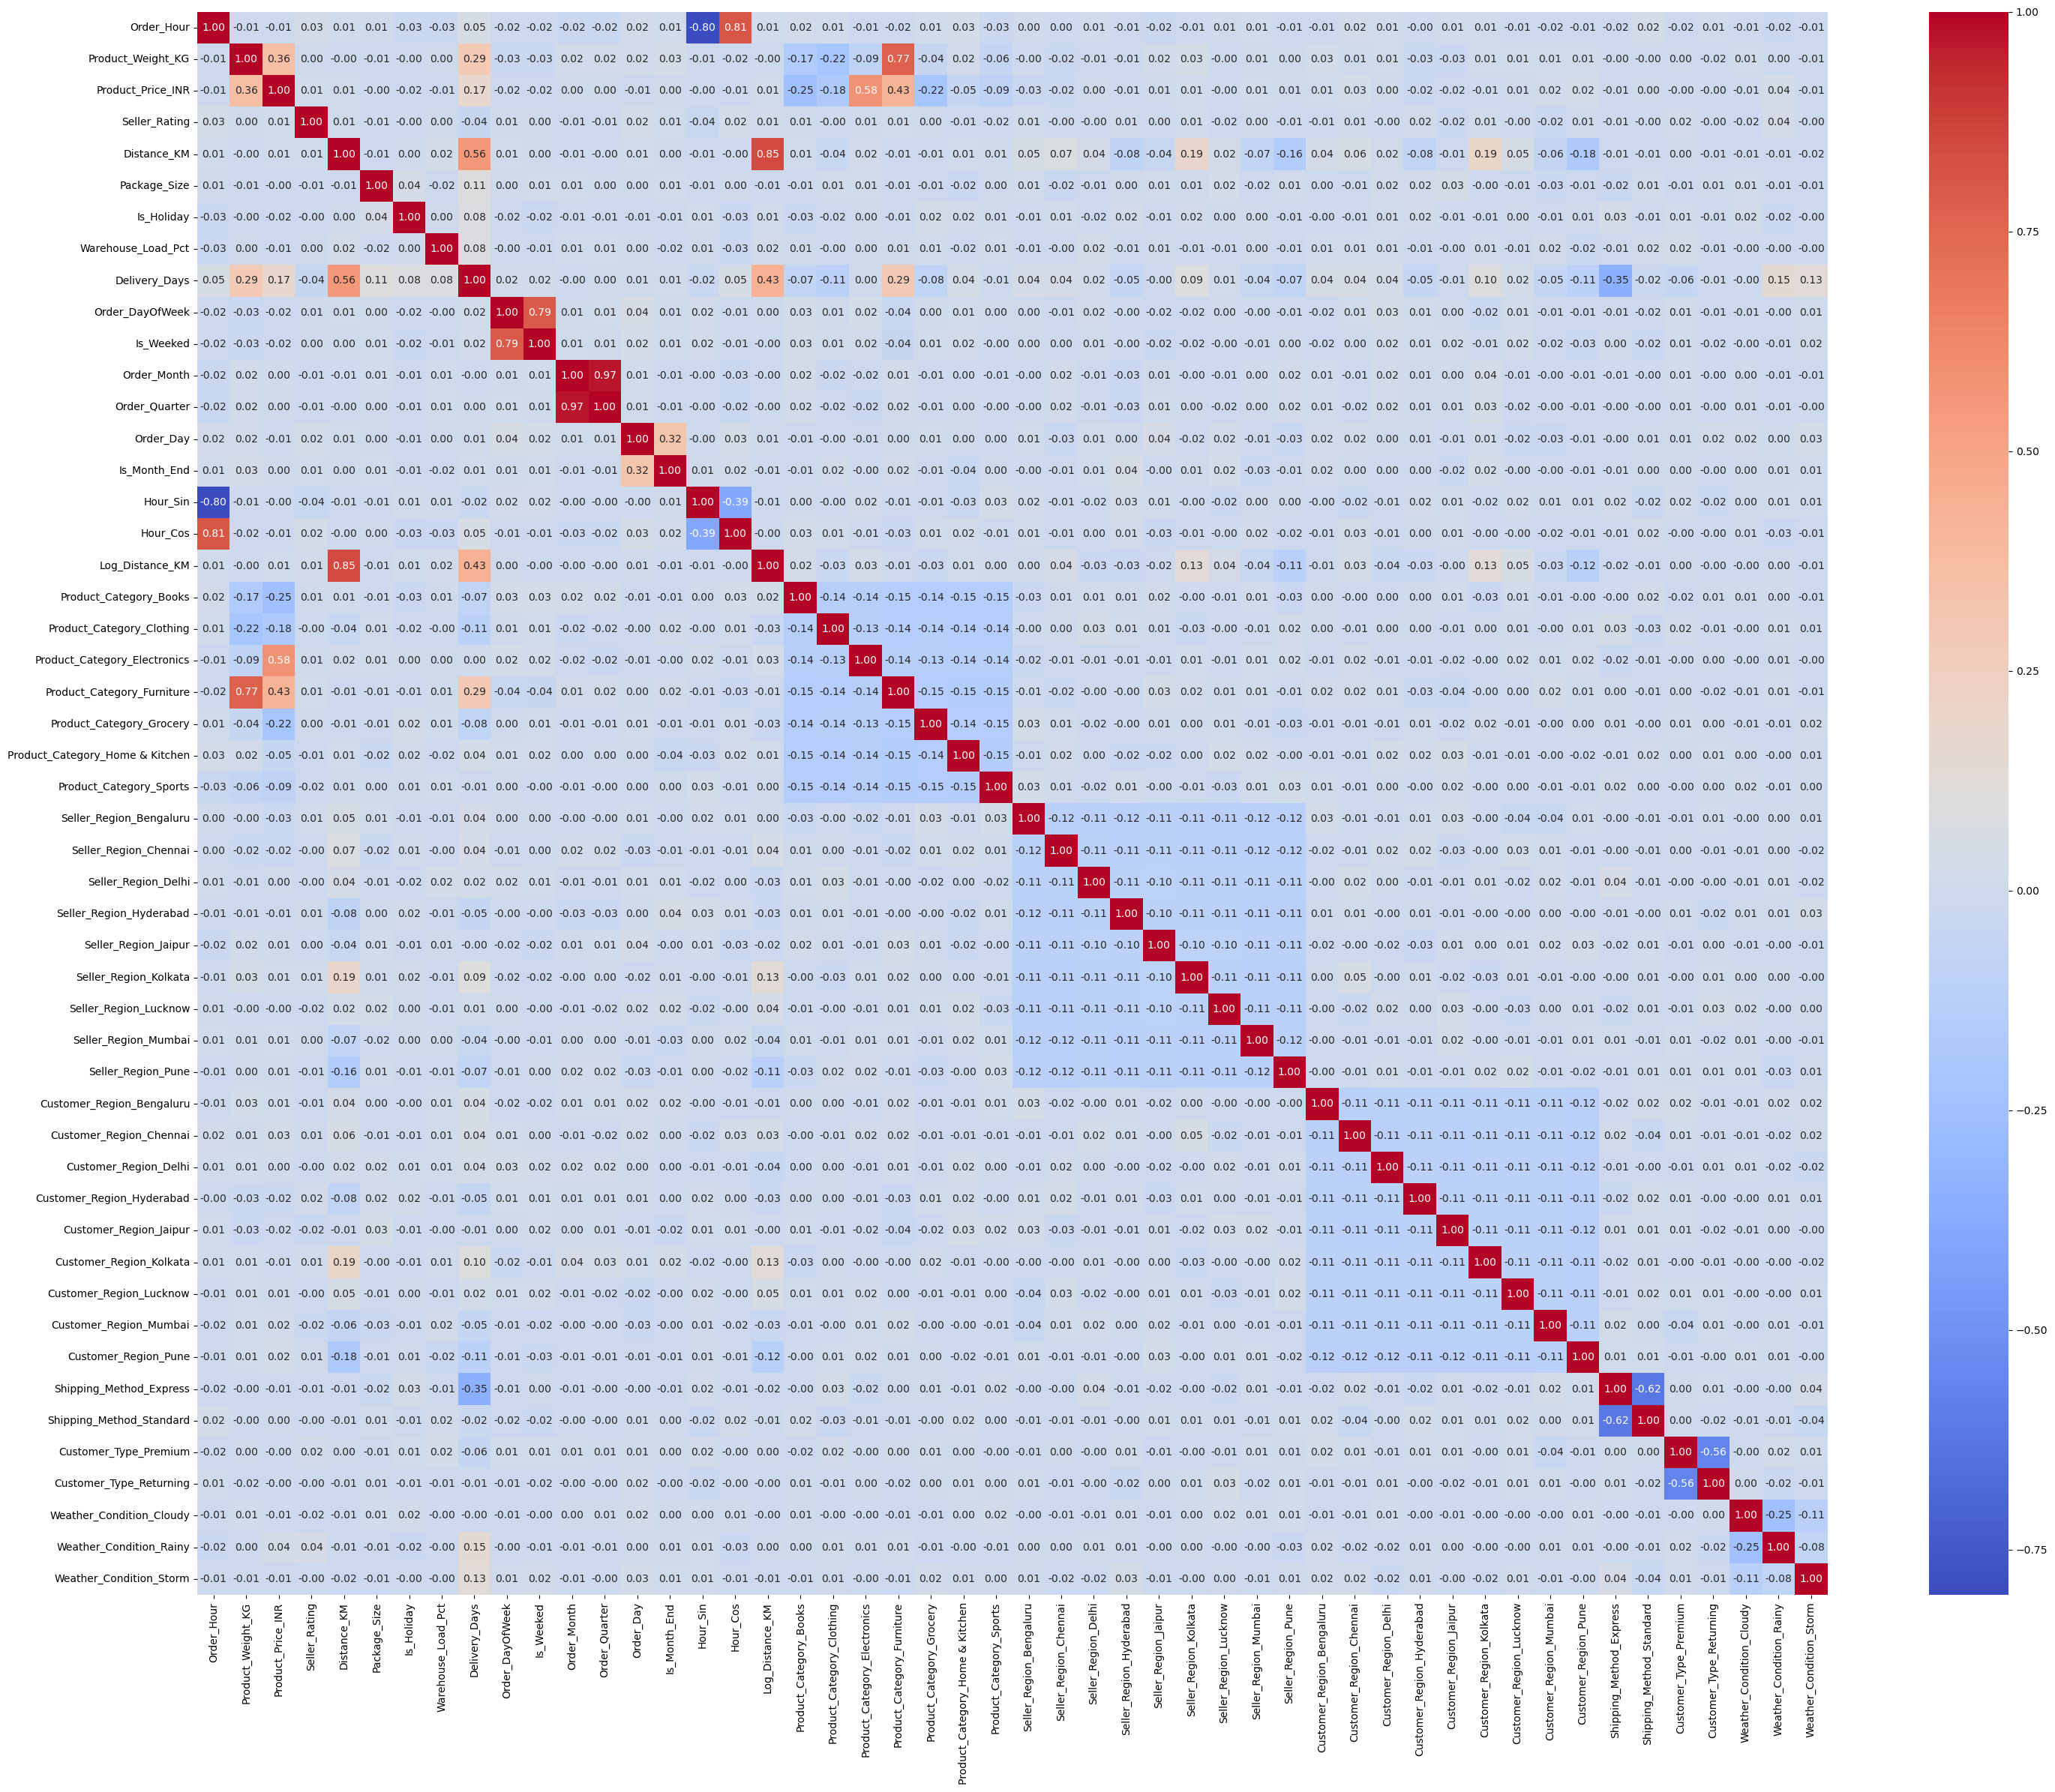

In [63]:
num_cols = df.select_dtypes(include=["number"]).columns

corr_matrix = df[num_cols].corr()

plt.figure(figsize=(30, 24))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.tight_layout()
plt.show()

# Train-Test-Split

In [65]:
X = df.drop(columns=["Order_ID", "Order_Date", "Payment_Method", "Order_Hour", "Distance_KM", "Order_Quarter", "Order_DayOfWeek", "Shipping_Method_Standard", "Delivery_Days"])
y = df["Delivery_Days"]

In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scaling

In [69]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train and Evaluate Models

In [72]:
# Linear Regression

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

y_pred = linear_model.predict(X_test_scaled)

# Evaluation
print("Linear Regression Model")
print(f"MAE = {mean_absolute_error(y_test, y_pred)}")
print(f"MSE = {mean_squared_error(y_test, y_pred)}")
print(f"R2 score = {r2_score(y_test, y_pred)}")

Linear Regression Model
MAE = 0.8432134423852947
MSE = 1.1491464565924834
R2 score = 0.48283028302433106


In [74]:
# KNN Regressor

knn_model = KNeighborsRegressor(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred = knn_model.predict(X_test_scaled)

# Evaluation
print("KNN Model")
print(f"MAE = {mean_absolute_error(y_test, y_pred)}")
print(f"MSE = {mean_squared_error(y_test, y_pred)}")
print(f"R2 score = {r2_score(y_test, y_pred)}")

KNN Model
MAE = 0.9782000000000001
MSE = 1.4818000000000002
R2 score = 0.33312061119959513


In [75]:
# Random Forest 

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)

y_pred = rf.predict(X_test_scaled)

# Evaluation
print("Random Forest Model")
print(f"MAE = {mean_absolute_error(y_test, y_pred)}")
print(f"MSE = {mean_squared_error(y_test, y_pred)}")
print(f"R2 score = {r2_score(y_test, y_pred)}")

Random Forest Model
MAE = 0.7565
MSE = 0.9069702
R2 score = 0.5918209389686997


In [77]:
# Gradient Boosting Regressor
gbr = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gbr.fit(X_train_scaled, y_train)
y_pred = gbr.predict(X_test_scaled)

# Evaluation
print("Gradient Boosting Regressor")
print(f"MAE = {mean_absolute_error(y_test, y_pred)}")
print(f"MSE = {mean_squared_error(y_test, y_pred)}")
print(f"R2 score = {r2_score(y_test, y_pred)}")

Gradient Boosting Regressor
MAE = 0.733263819815442
MSE = 0.8444871599940602
R2 score = 0.6199412328879548
